# PPI-Caliper Reproduction Walkthrough

Use released prediction scores to learn how PPI-Caliper selects thresholds, then reproduce the paper experiments. (For your own data, see [README Quick Start](../README.md#quick-start).) Full walkthrough starts at section 4.

## 0. Set up

The experiments use 100 seeds for PLM-Interact, and 30 for MINT. Outputs go to `results/tutorial/paper/`.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data/data_sources.json").is_file()
     and (path / "src/PPICaliper.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Start Jupyter inside the PPI-Caliper repository.")

AUTO_DOWNLOAD = True
DATA_DIR = REPO_ROOT / "data"

SEEDS = {"plm-interact": 100, "mint": 30}
RUN_ROOT = REPO_ROOT / "results/tutorial/paper"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
print(f"PLM-Interact seeds: {SEEDS['plm-interact']}; MINT seeds: {SEEDS['mint']}")
print(f"Outputs: {RUN_ROOT.relative_to(REPO_ROOT)}")

PLM-Interact seeds: 100; MINT seeds: 30
Outputs: results/tutorial/paper


### Load the tools

Import PPI-Caliper and the shared experiment utilities. The `run_script` function runs each analysis command and saves its log.

In [2]:
import os
import subprocess
from functools import partial
import pandas as pd
from IPython.display import display

os.environ.setdefault("MPLCONFIGDIR", str(RUN_ROOT / ".matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(RUN_ROOT / ".cache"))
TUTORIALS_DIR = REPO_ROOT / "tutorials"
for directory in (TUTORIALS_DIR, REPO_ROOT / "src"):
    sys.path.insert(0, str(directory))

from PPICaliper import PPICaliper
from utils.sampling import stratified_half_split
from utils.inputs import prediction_path
from within_species.plot import plot_results as plot_within
from transfer_species.plot import plot_heatmap
from utils.figure_style import show_plot

show_plot = partial(show_plot, output_dir=RUN_ROOT / "notebook_figures")
LOG_ROOT = RUN_ROOT / "logs"
LOG_ROOT.mkdir(exist_ok=True)


def run_script(script, *arguments, python=sys.executable):
    log = LOG_ROOT / f"{Path(script).stem}-{len(list(LOG_ROOT.glob('*.log'))):03d}.log"
    command = [str(python), str(REPO_ROOT / script), *map(str, arguments)]
    with log.open("w") as stream:
        result = subprocess.run(command, cwd=REPO_ROOT, stdout=stream, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(f"{script} failed. See {log}\n{log.read_text()[-2000:]}")
    print(f"Completed {script}")

## 1. Load scores

The next cell downloads the pinned [Hugging Face release](https://huggingface.co/datasets/lidehan/PPI-Caliper-predictions). (TODO: Access currently requires `hf auth login` with an authorized account.)

The dataset contains prediction scores and saved reference results. Original sequences are downloaded separately for the optional steps at the end. Set `DATA_DIR` above to use another disk.

In [3]:
if AUTO_DOWNLOAD:
    run_script("data/download_data.py", "--destination", DATA_DIR)
run_script("data/preprocess_data.py", "--data-dir", DATA_DIR)

Completed data/download_data.py


Completed data/preprocess_data.py


### Inspect the inputs

Each row is a protein pair: `p_ab` is its prediction score and `label` is 0 or 1. Higher scores indicate stronger evidence for interaction.

In [4]:
MODELS = ("humanv11", "humanv12")
Q_LEVELS = [0.1, 0.2, 0.3]


display(pd.read_csv(prediction_path("humanv11", "ecoli", data_root=DATA_DIR),
                    usecols=["p_ab", "label"])[["p_ab", "label"]].head())

,p_ab,label
0,0.999904,1
1,0.999887,1
2,0.999877,1
3,0.999868,1
4,0.999490,1


## 2. Same-species example

Use E. coli scores from PLM-Interact humanV11. Split the pairs into calibration and test halves, preserving the label proportions. PPI-Caliper converts scores to quantiles using the calibration score distribution, then applies that same mapping to the test scores.

In [5]:
demo = pd.read_csv(prediction_path("humanv11", "ecoli", data_root=DATA_DIR), float_precision="round_trip")
calibration_idx, test_idx = stratified_half_split(demo.label.to_numpy(), seed=0, species_index=0)
calibration = demo.iloc[calibration_idx]
test = demo.iloc[test_idx]

PPI-Caliper draws ten **bootstrap calibration batches**: random samples from the **labeled calibration half**, allowing repeats. Each sampled pair keeps its score and label. Each batch contains 10% of the full dataset's pairs.

For each candidate threshold, it calculates the false-discovery proportion (FDP) in each batch, then averages across batches. With the default settings, it chooses the lowest threshold where this average stays at or below the requested FDR at that threshold and every higher threshold.

Apply the returned score threshold to the separate test pairs, selecting those with scores at or above it. A threshold of `inf` means no pairs are selected. Recompute thresholds when using a different target file.

In [6]:
caliper = PPICaliper(seed=0, species_index=0, query_size=round(len(demo) / 10))
threshold_results = caliper.ppicaliper(
    calibration.p_ab.to_numpy(), calibration.label.to_numpy(),
    test.p_ab.to_numpy(), Q_LEVELS,
)
demo_results = pd.DataFrame([
    {"target_fdr": result.target_fdr, "cutoff_score": result.cutoff_score}
    for result in threshold_results
])
demo_results.to_csv(RUN_ROOT / "single_split_demo.csv", index=False)
display(demo_results.style.format({"target_fdr": "{:.1f}", "cutoff_score": "{:.17g}"}).hide(axis="index"))

target_fdr,cutoff_score
0.1,0.99989271163940441
0.2,0.99986350536346436
0.3,0.99975556135177601


## 3. Cross-species example: mouse -> yeast

Mouse scores and labels determine the quantile threshold. A separate yeast sample supplies scores for the yeast mapping. Apply the threshold to yeast test pairs.

The benchmark labels preserve class proportions when splitting. The yeast mapping and selection steps use only scores. Cross-species performance is evaluated in Section 4.

The table gives the score cutoff for each requested FDR level.

In [7]:
mouse = pd.read_csv(prediction_path("humanv11", "mouse", data_root=DATA_DIR))
yeast = pd.read_csv(prediction_path("humanv11", "yeast", data_root=DATA_DIR))
source_idx, _ = stratified_half_split(mouse.label.to_numpy(), seed=0, species_index=2)
mapping_idx, target_idx = stratified_half_split(yeast.label.to_numpy(), seed=0, species_index=4)
source = mouse.iloc[source_idx]
target_mapping = yeast.iloc[mapping_idx]
target_test = yeast.iloc[target_idx]

transfer_thresholds = PPICaliper(seed=0, species_index=2).ppicaliper(
    source.p_ab.to_numpy(), source.label.to_numpy(),
    target_test.p_ab.to_numpy(), Q_LEVELS,
    target_mapping_scores=target_mapping.p_ab.to_numpy(),
)
transfer_demo = pd.DataFrame([
    {"target_fdr": result.target_fdr, "cutoff_score": result.cutoff_score}
    for result in transfer_thresholds
])
transfer_demo.to_csv(RUN_ROOT / "cross_species_demo.csv", index=False)
display(transfer_demo.style.format({"target_fdr": "{:.1f}", "cutoff_score": "{:.17g}"}).hide(axis="index"))

target_fdr,cutoff_score
0.1,0.99673908948898315
0.2,0.56687366962432861
0.3,0.0213271602988243


## 4. Reproduce the paper results

### Within species

Run both predictors and model versions across five species. Each split calls `PPICaliper` to select score cutoffs, then measures FDP, power, and accuracy on the held-out pairs.

The three rows show mean FDP, power (the fraction of true interactions recovered), and accuracy (the fraction of pairs classified correctly), at target FDR 0.1–0.9. Mean FDP across splits is empirical FDR. Shading shows pointwise 95% Student-t intervals across splits of this benchmark.

In [8]:
within_results = {}
for predictor, n_seeds in SEEDS.items():
    output = RUN_ROOT / predictor / "within"
    run_script("tutorials/within_species/run_experiments.py",
               "--predictor", predictor, "--data-root", DATA_DIR,
               "--n-seeds", n_seeds, "--output-dir", output)
    within_results[predictor] = pd.read_csv(output / "method1_all_seed_results.csv")

Completed tutorials/within_species/run_experiments.py


Completed tutorials/within_species/run_experiments.py


Compare FDP in the top row with the dotted diagonal line. Values below the line are conservative on these benchmark splits; values above it exceed the requested target on average.

Compare power and accuracy in the next two rows. Accuracy can be high even when few true interactions are recovered, because most benchmark pairs are negative.

MINT V12 results differ from the paper. The earlier MINT code accepts the lowest threshold whose mean calibration FDP meets the target; this notebook also requires every higher threshold to pass.

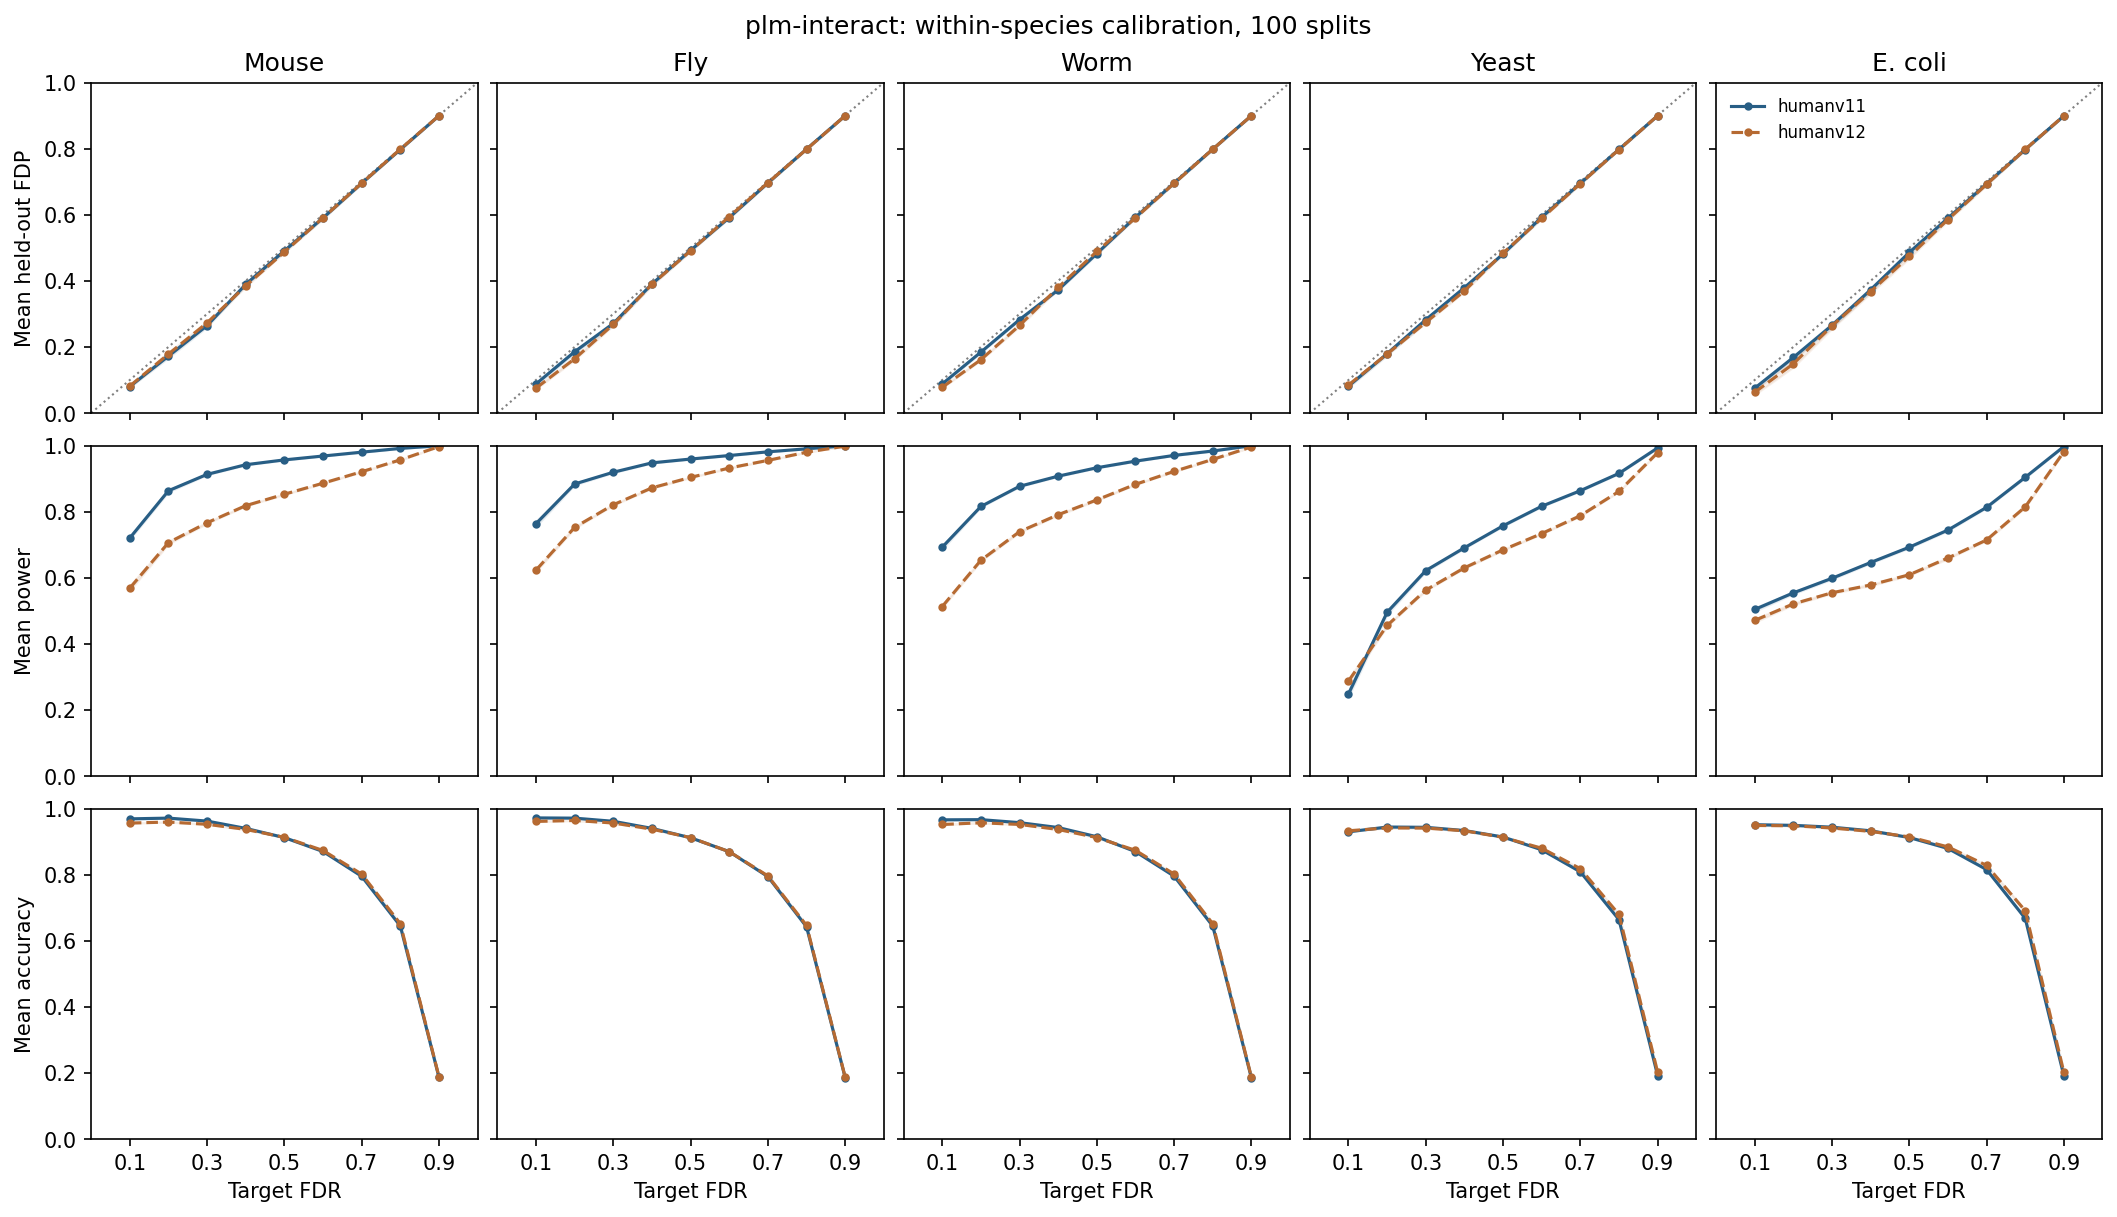

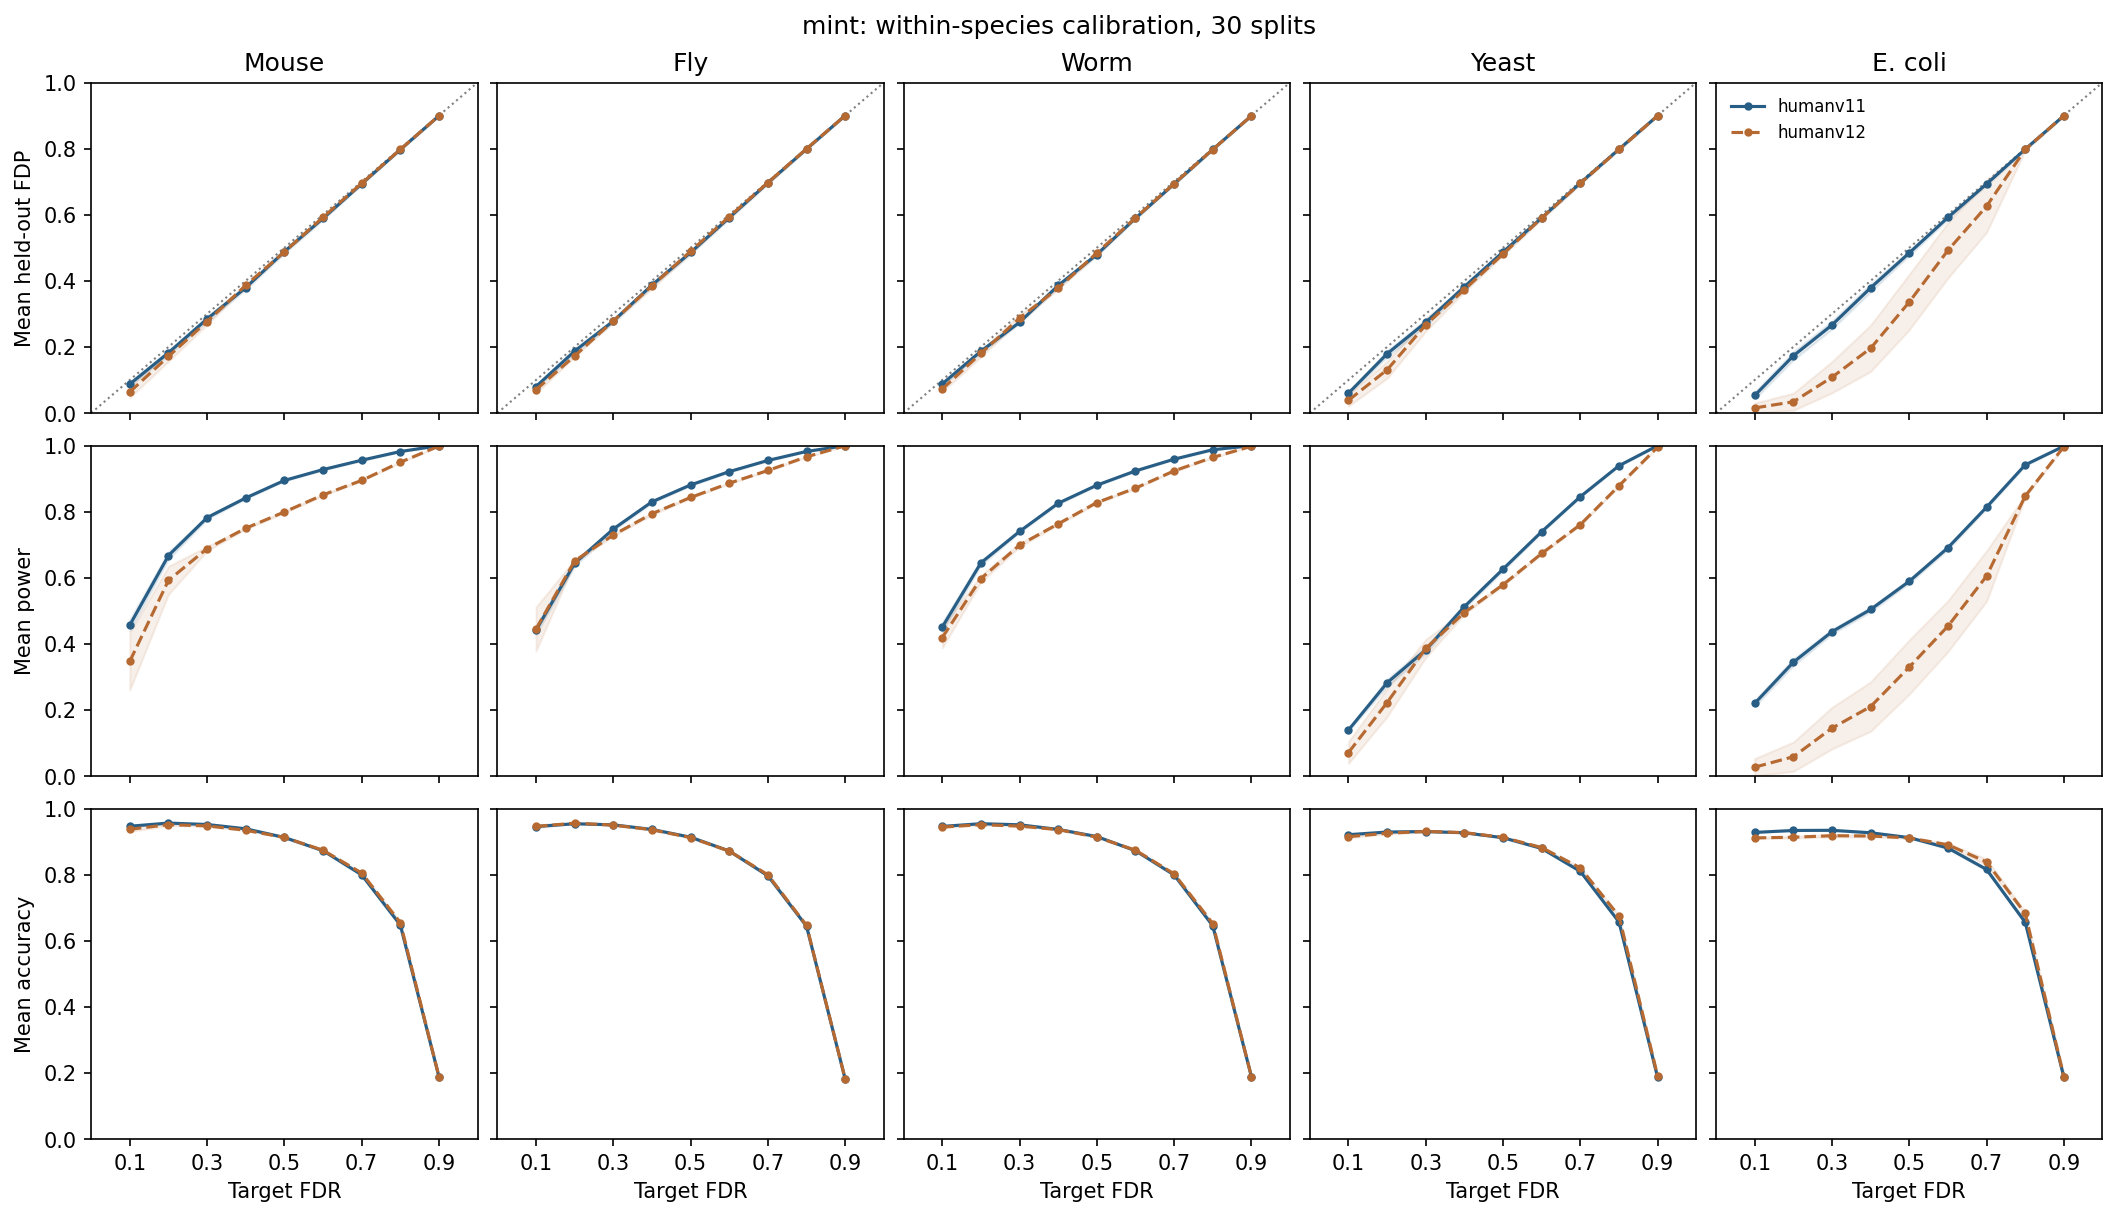

In [9]:
for predictor, results in within_results.items():
    show_plot(plot_within(results, predictor), f"{predictor}_within_metrics")

### Across species

Run all 20 ordered source-to-target transfers for both predictors and model versions. Each target has a separate mapping half and test half. `PPICaliper` uses the source calibration data and target mapping scores to select cutoffs for the target test pairs. Target labels are used for splitting and evaluation, not threshold selection.

The heatmap shows mean test FDP minus the requested FDR of 0.1. Positive values exceed the requested level. Plots of FDP, power, and accuracy across all target FDR levels are saved in each predictor’s `transfer/figures/` folder.

In [10]:
transfer_results = {}
classification_metrics = {}
for predictor, n_seeds in SEEDS.items():
    output = RUN_ROOT / predictor / "transfer"
    run_script("tutorials/transfer_species/run_experiments.py",
               "--predictor", predictor, "--data-root", DATA_DIR,
               "--n-seeds", n_seeds, "--output-dir", output)
    transfer_results[predictor] = pd.read_csv(output / "all_seed_results.csv")
    classification_metrics[predictor] = pd.read_csv(output / "classification_metrics.csv")

Completed tutorials/transfer_species/run_experiments.py


Completed tutorials/transfer_species/run_experiments.py


Rows are source species; columns are target species. Negative values are conservative. All panels use the same color range. AUPRC below each target species summarizes the quality of its original prediction scores; higher is better.

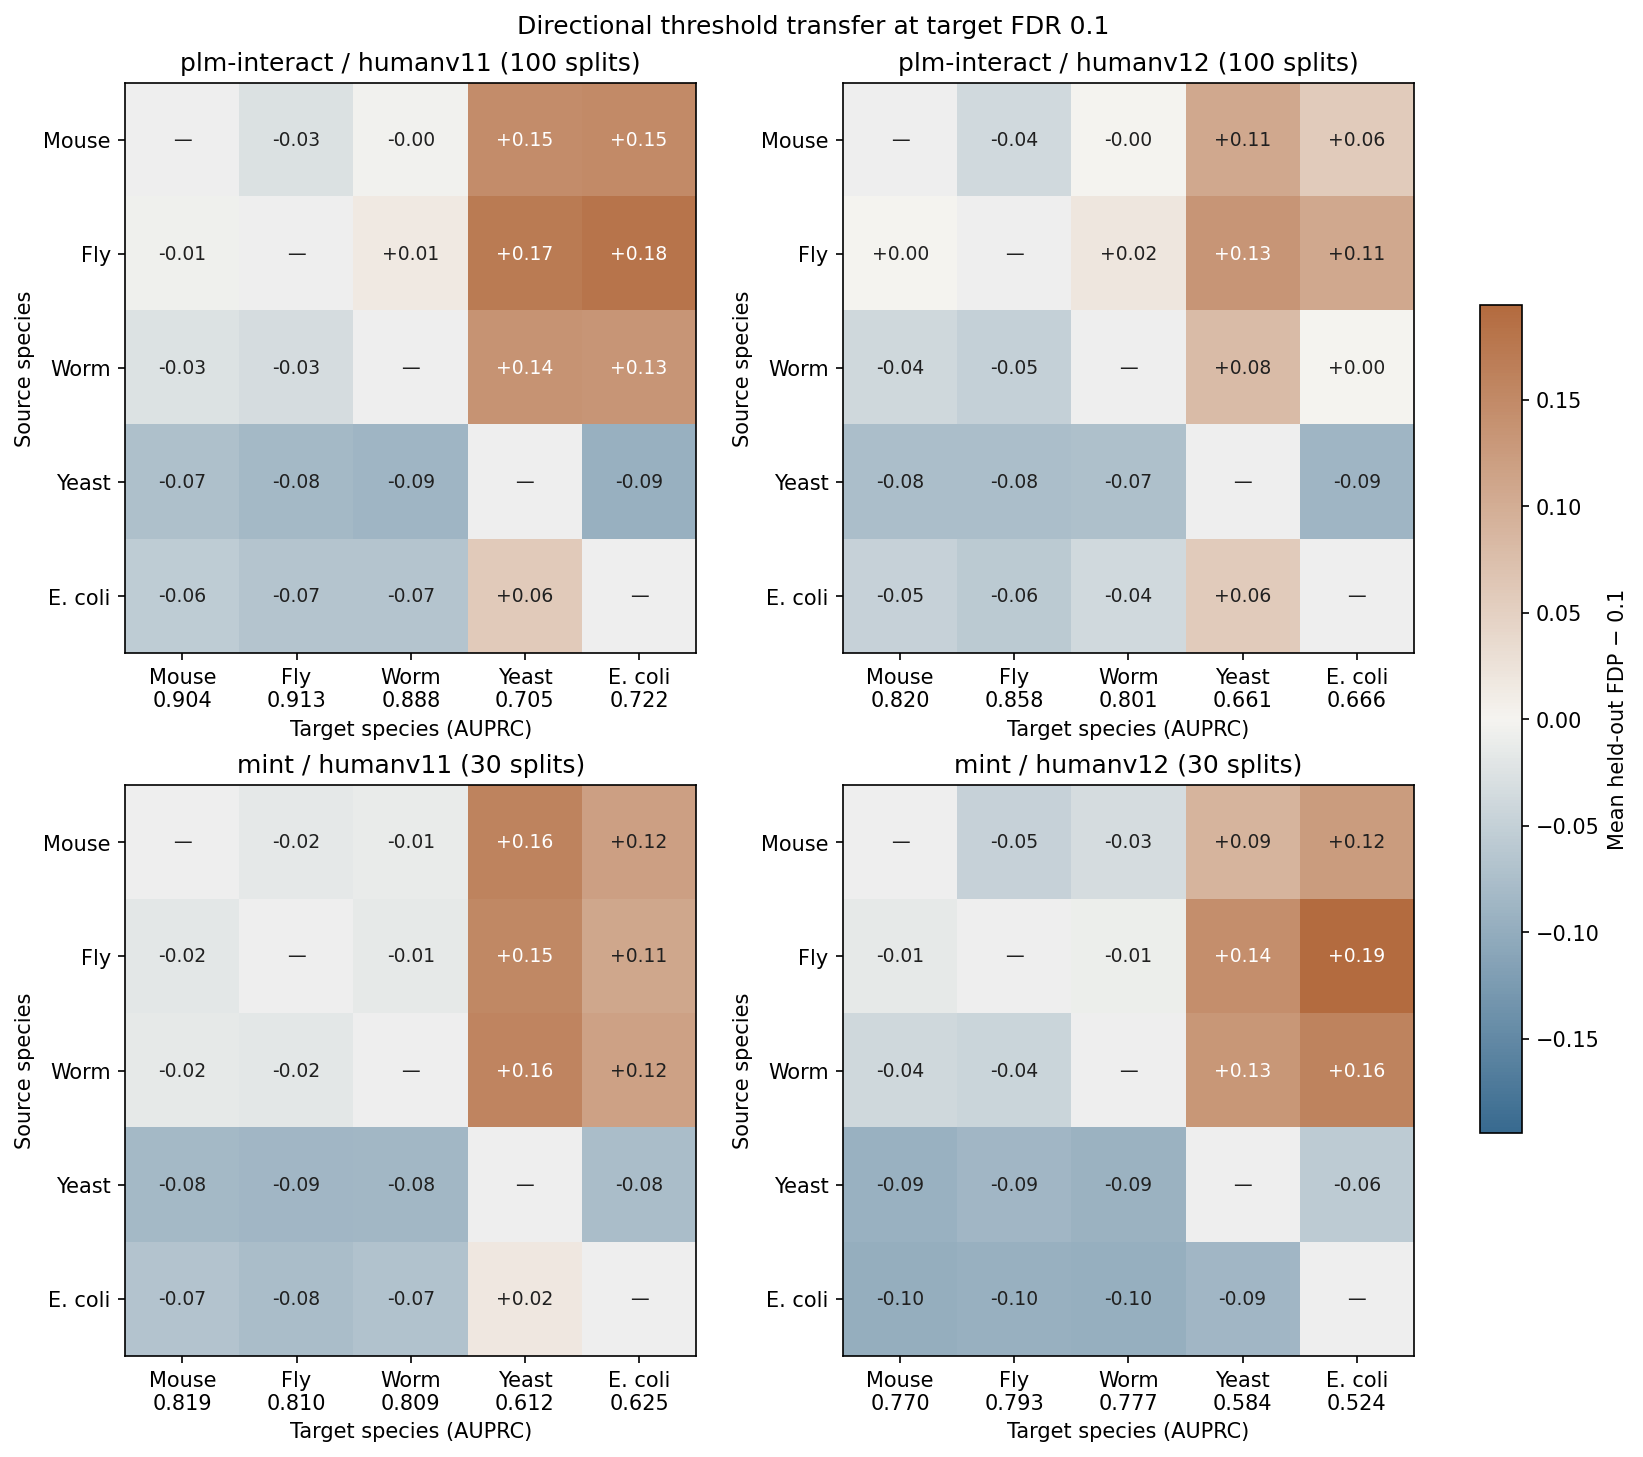

In [11]:
show_plot(plot_heatmap(transfer_results, classification_metrics), "transfer_fdp_gap")

## 5. Optional: generate prediction scores

Generate scores from the original benchmark sequences. Set either option below to `True` to run that workflow.

In [12]:
RUN_PLM_INFERENCE = False
RUN_MINT_TRAINING = False
GPU_DEVICE = "cuda:0"

if RUN_PLM_INFERENCE or RUN_MINT_TRAINING:
    if AUTO_DOWNLOAD:
        run_script("data/download_data.py", "--only-upstream", "--destination", DATA_DIR)
    run_script("data/preprocess_data.py", "--only-upstream", "--data-dir", DATA_DIR)

### PLM-Interact

Score the five species with the released humanV11 and humanV12 checkpoints. No fine-tuning is needed. See the [PLM-Interact scoring guide](computing_scores/plm_interact/README.md) for setup and options. Scores go to `results/plm-interact/scores/<model>/`.

In [13]:
if RUN_PLM_INFERENCE:
    run_script("tutorials/computing_scores/plm_interact/download_models.py")
    for model in MODELS:
        run_script("tutorials/computing_scores/plm_interact/score.py",
                   "--model", model, "--data-root", DATA_DIR / "raw", "--device", GPU_DEVICE)

### MINT

Follow the [MINT setup and training guide](computing_scores/mint/README.md) to install the official MINT code and download its encoder checkpoint. For each version, extract embeddings, train the prediction head, and score the five species. The encoder stays frozen. Scores go to `results/mint/scores/<version>/`.

In [14]:
if RUN_MINT_TRAINING:
    for version in ("v11", "v12"):
        run_script("tutorials/computing_scores/mint/extract_embeddings.py",
                   "--version", version, "--device", GPU_DEVICE)
        run_script("tutorials/computing_scores/mint/train.py",
                   "--version", version, "--device", GPU_DEVICE)
        run_script("tutorials/computing_scores/mint/score.py",
                   "--version", version, "--device", GPU_DEVICE)